# ECOSTRESS ET: original summer 2019 and 2020 scene evidence

Real NASA ECOSTRESS ECO3ETPTJPL.001 archived statistics (283 2019 scenes and 358 2020 scenes), with two sample GeoTIFFs. Product ETdaily is **daily latent heat flux in W/m²**, not precipitation or water depth. Historical Version 1 is used to preserve 2022 provenance.

In [1]:
from pathlib import Path
import sys
PROJECT = Path.cwd()
if not (PROJECT / 'src').exists():
    PROJECT = PROJECT.parent
assert (PROJECT / 'src').exists(), 'Run notebook from repository root or notebooks/'
sys.path.insert(0, str(PROJECT))
from IPython.display import display, Image
import pandas as pd


## Scene-level quality and temporal coverage
These tables describe per-granule ET summaries. The ISS sampling geometry is uneven and scenes may overlap spatially, so comparing unweighted or count-weighted overall summer means would not prove a physical change.

In [2]:
from src.pipeline import compute_ecostress, RESULTS
scenes, summary, footprints = compute_ecostress()
print('Total real scenes:',len(scenes))
display(summary.round(2))

Total real scenes: 641


,year,month,n_scenes,median_of_scene_means_W_m2,sum_scene_valid_pixels
0,2019,6,73,118.38,898543250
1,2019,7,74,176.49,1027366170
2,2019,8,136,118.73,1886718586
3,2020,6,189,99.12,2242438985
4,2020,7,95,181.22,1091513632
5,2020,8,74,131.89,602646277


## Distribution of archived scene means
These boxes summarize *which scenes were archived*, not a matched-location surface ET comparison.

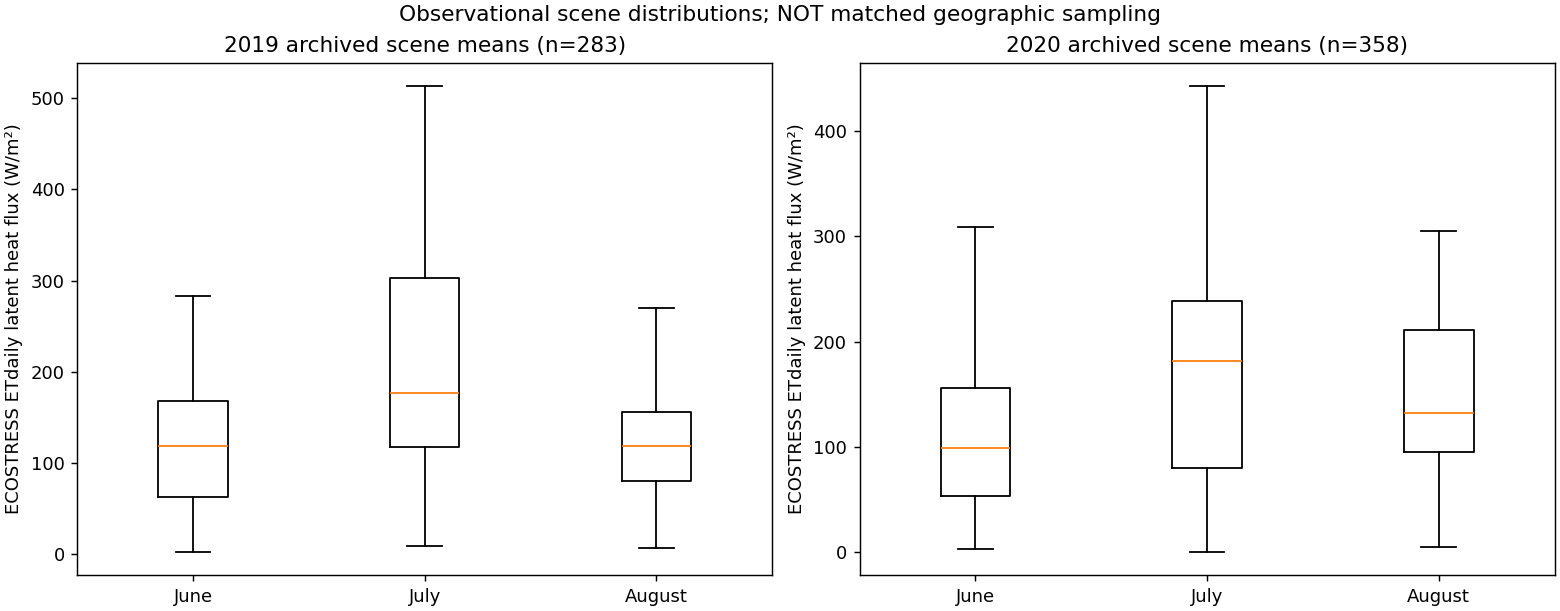

In [3]:
display(Image(filename=str(RESULTS/'04_ecostress_scene_sample_distribution.png'),width=900))

## Explicit spatial comparability check
The available example 2019 and 2020 GeoTIFFs do **not** overlap geographically. A direct 2019-minus-2020 raster difference would therefore be a fabricated result.

,year,left,right,bottom,top,rows,columns
0,2019,118.583,119.907,46.524,51.337,7648,2104
1,2020,101.505,108.110,41.586,43.727,3394,10470


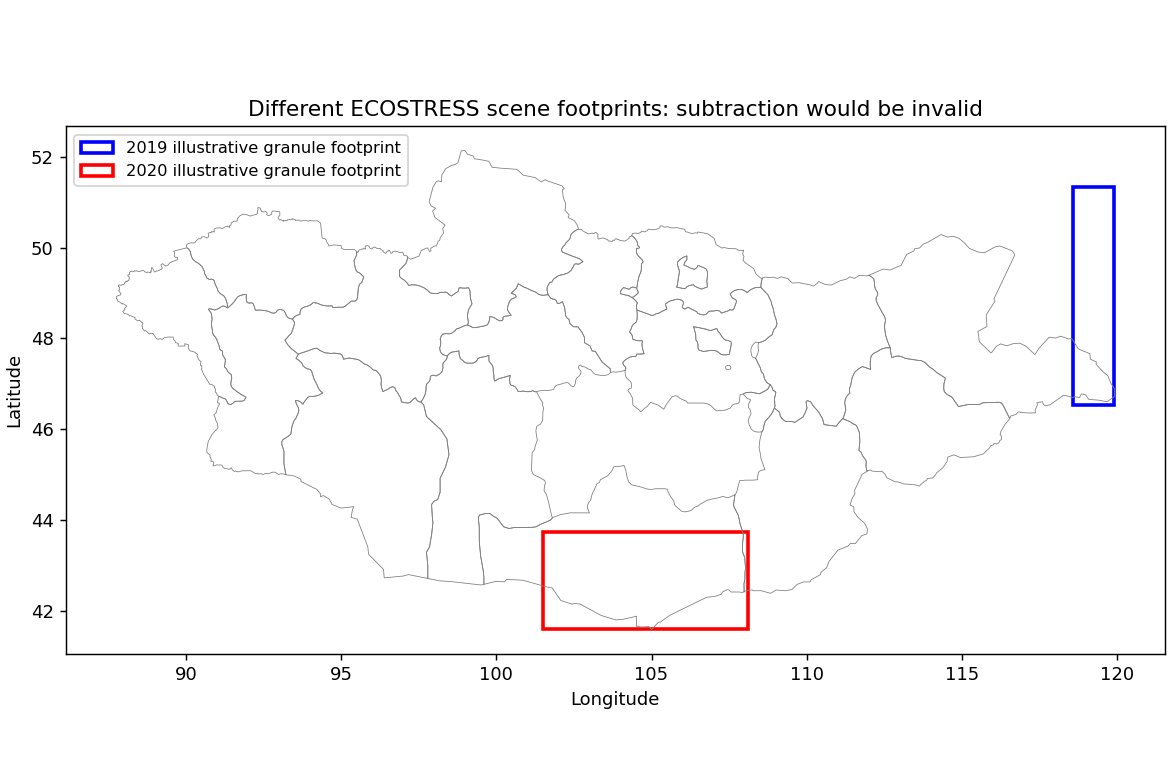

In [4]:
display(pd.DataFrame(footprints)[['year','left','right','bottom','top','rows','columns']].round(3))
display(Image(filename=str(RESULTS/'05_ecostress_footprints_do_not_overlap.png'),width=900))

## Technical qualification
A complete location-matched multi-granule ET comparison would require additional ECOSTRESS scenes, consistent cloud masking, geographic sampling and temporal balancing. This notebook deliberately makes no drought or mortality inference from mismatched scene distributions.